In [1]:
import io
import boto3
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
df_preview = pd.read_csv(
    "saveecobot_air_quality.csv",
    nrows=5
)

display(df_preview)

,city_id,aqi,pm25,logged_at
0,1,63,18.1990,2019-02-27 20:00:00
1,1,64,22.1627,2019-02-27 21:00:00
2,1,67,22.0240,2019-02-27 22:00:00
3,1,68,20.9790,2019-02-27 23:00:00
4,1,70,22.6410,2019-02-28 00:00:00


In [3]:
print(df_preview.columns.tolist())

['city_id', 'aqi', 'pm25', 'logged_at']


In [ ]:
BUCKET = "lab4-danylo-air-quality-2026-2410"
KEY = "data/saveecobot_air_quality.csv"

s3 = boto3.client("s3")

/home/ec2-user/air-env/lib64/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)


In [5]:
s3.head_bucket(Bucket=BUCKET)

print("Підключення до S3 успішне")

Підключення до S3 успішне


In [7]:
response = s3.head_object(
    Bucket=BUCKET,
    Key=KEY
)

print("Файл знайдено в S3")
print("Розмір файлу:", response["ContentLength"], "байт")

Файл знайдено в S3
Розмір файлу: 242051346 байт


In [8]:
obj = s3.get_object(
    Bucket=BUCKET,
    Key=KEY
)

print("Файл відкрито для читання з S3")

Файл відкрито для читання з S3


In [9]:
reader = pd.read_csv(
    obj["Body"],
    usecols=["aqi", "logged_at"],
    chunksize=100000
)

print("CSV підготовлено до читання частинами")

CSV підготовлено до читання частинами


In [10]:
aqi_sum = pd.Series(0.0, index=range(24))
aqi_count = pd.Series(0, index=range(24))

In [11]:
for chunk in reader:
    chunk["logged_at"] = pd.to_datetime(
        chunk["logged_at"],
        errors="coerce"
    )

    chunk["aqi"] = pd.to_numeric(
        chunk["aqi"],
        errors="coerce"
    )

    chunk = chunk.dropna(
        subset=["logged_at", "aqi"]
    )

    chunk["hour"] = chunk["logged_at"].dt.hour

    grouped_sum = chunk.groupby("hour")["aqi"].sum()
    grouped_count = chunk.groupby("hour")["aqi"].count()

    aqi_sum = aqi_sum.add(grouped_sum, fill_value=0)
    aqi_count = aqi_count.add(grouped_count, fill_value=0)

print("Обробку CSV завершено")

Обробку CSV завершено


In [12]:
average_aqi = aqi_sum / aqi_count

In [13]:
hourly_aqi = pd.DataFrame({
    "hour": range(24),
    "average_aqi": average_aqi.values
})

hourly_aqi["average_aqi"] = hourly_aqi["average_aqi"].round(2)

display(hourly_aqi)

,hour,average_aqi
0,0,40.52
1,1,39.70
2,2,38.70
3,3,37.71
4,4,36.93
5,5,36.33
6,6,36.11
7,7,36.36
8,8,36.88
9,9,37.06


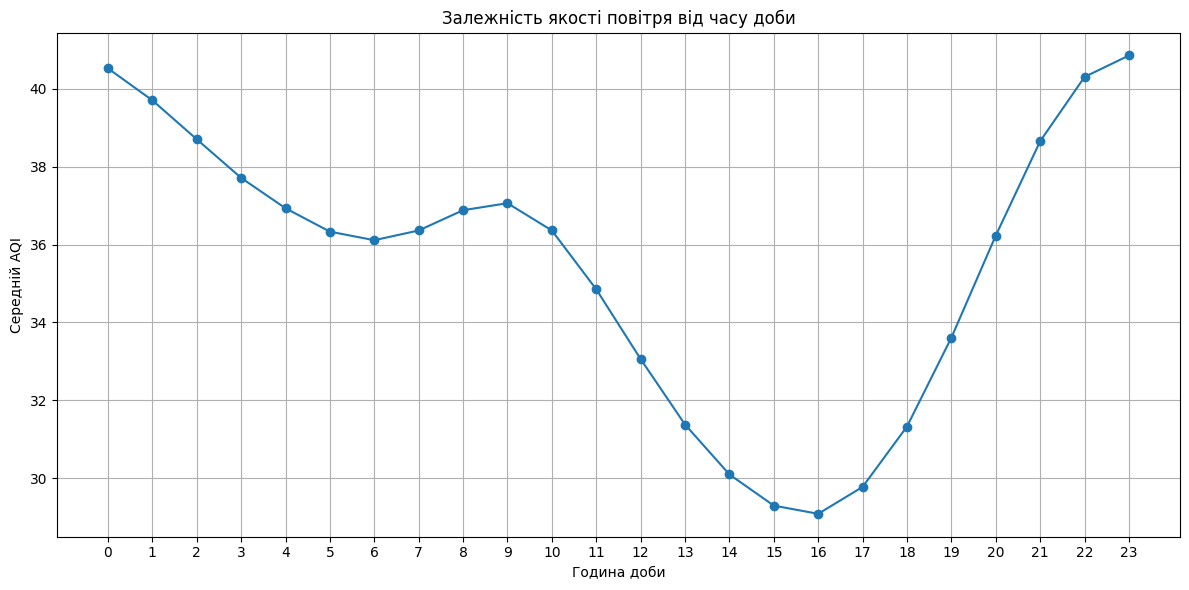

In [14]:
plt.figure(figsize=(12, 6))

plt.plot(
    hourly_aqi["hour"],
    hourly_aqi["average_aqi"],
    marker="o"
)

plt.xlabel("Година доби")
plt.ylabel("Середній AQI")
plt.title("Залежність якості повітря від часу доби")

plt.xticks(range(24))
plt.grid(True)

plt.tight_layout()
plt.show()

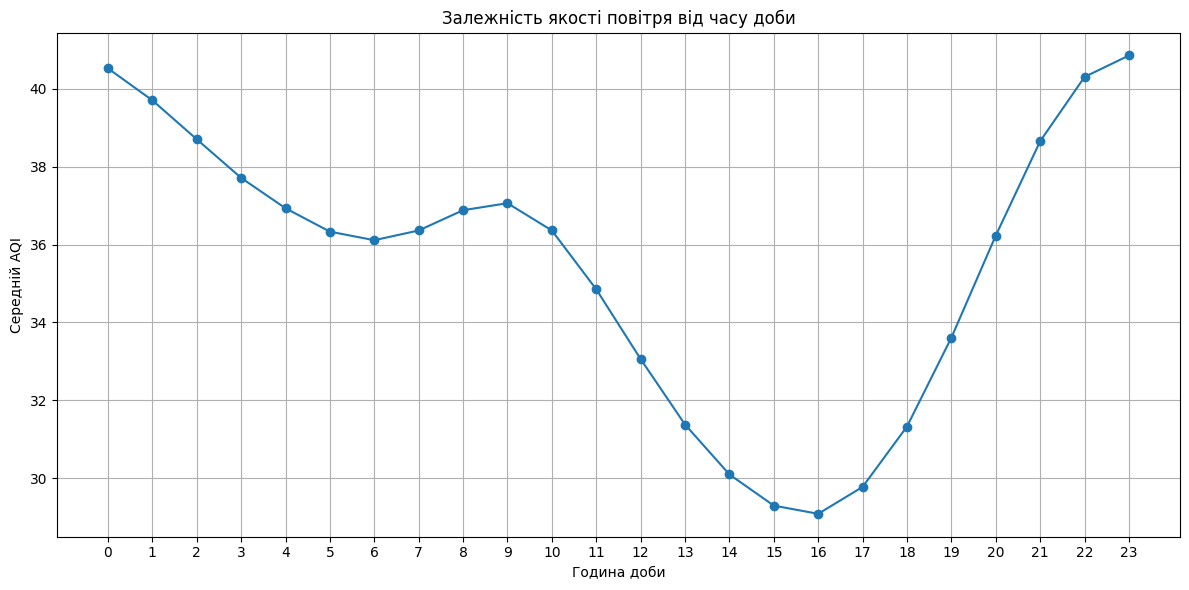

In [15]:
plt.figure(figsize=(12, 6))

plt.plot(
    hourly_aqi["hour"],
    hourly_aqi["average_aqi"],
    marker="o"
)

plt.xlabel("Година доби")
plt.ylabel("Середній AQI")
plt.title("Залежність якості повітря від часу доби")

plt.xticks(range(24))
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "air_quality_by_hour.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [16]:
s3.upload_file(
    "air_quality_by_hour.png",
    BUCKET,
    "plots/air_quality_by_hour.png"
)

print("Графік успішно завантажено до S3")

Графік успішно завантажено до S3


In [17]:
response = s3.list_objects_v2(
    Bucket=BUCKET
)

for obj in response.get("Contents", []):
    print(obj["Key"])

data/saveecobot_air_quality.csv
plots/air_quality_by_hour.png
